# **Tutorial 1: My first accelerator**

In [1]:
from IPython.display import FileLink

In [2]:
%%html
<a href="https://xsuite.readthedocs.io/en/latest/apireference.html">XSUITE reference manual</a>

<div style="font-size: 16px;">
    
# **Questions:**

#### **My first FODO**
<table style="width:100%; border-collapse:collapse; font-size:16px;">
  <tr>
    <td style="width:50%; vertical-align:top; padding:15px;">
        <strong>FODO cell specifications:</strong>
        <ul>
            <li>L<sub>cell</sub> = 100 m</li> 
            <li>ld<sub>1</sub> = 0 m, ld<sub>2</sub> = 49 m, ld<sub>3</sub> = 49 m</li>
            <li>L<sub>q</sub> = 1 m</li>
            <li>f = 200 m (k · L<sub>q</sub> = 1 / f)</li>
            <li>Beam specifications: protons, E<sub>tot</sub> = 450 GeV, $\epsilon_n^{x,y}$= 3 mm·mrad </strong></p>
        </ul>
     </td>
        <td style="width:60%; text-align:center; padding:15px;">
        <img src="../Figures/Tutorial1_FODO.png" style="max-width:100%; height:auto;">
    </td>
  </tr>
</table>

#### 1. Compute and plot the periodic TWISS functions of the provided FODO lattice. 

- What is the maximum $\beta$-function?

#### 2. Try to run the Twiss command with a focal length of 20 m. 

- Why do you get an error message?
    
#### 3. Reduce the focusing strength of the quadrupoles by half. 

- What is its effect on $\beta_{max}$, $\beta_{min}$? And the phase advance $\Delta \mu$?

#### 4. Compute the maximum beam size, $\sigma_{x,y}$, before and after reducing the strength of the quadrupoles.

----
#### **My first Transfer Line**
<table style="width:100%; border-collapse:collapse; font-size:16px;">
  <tr>
    <td style="width:50%; vertical-align:top; padding:15px;">
        <strong>Transfer line specifications:</strong>
        <ul>
            <li>L<sub>cell</sub> = 6.4 m</li>
            <li>ld<sub>1</sub> = 1 m, ld<sub>2</sub> = 1 m, ld<sub>3</sub> = 4 m</li>
            <li>L<sub>q</sub> = 0.2 m</li>
            <li> Half aperture of quadrupoles, $r_{in}$ = 0.03 m
            <li> Normal-conducting technology
            <li>Beam specifications: proton, E<sub>k</sub> = 10 MeV/u, $\epsilon_g^{x,y}$= 1.8 mm·mrad 
            <li>Initial TWISS parameters: $\beta_{x}$ = 0.9747 m, $\beta_{y}$ = 0.6867 m, $\alpha_{x}$ = -1.7857, $\alpha_{y}$ = -1.3676
        </ul>
     </td>
        <td style="width:60%; text-align:center; padding:15px;">
        <img src="../Figures/Tutorial1_FODO.png" style="max-width:100%; height:auto;">
    </td>
  </tr>
</table>

#### 5. Optimize the quadrupole's strength of the transfer line to simultaneously: 

- Increased beam size at the end of the transfer line: $\sigma^{END}_{x,y} = 3 cm$
- Ensure sufficient aperture margin inside the quadrupoles, impose a
  $5\sigma$ safety criterion: $\beta^{quad}_{x,y} < \frac{(0.03/5)^2}{\epsilon_{g}^{x,y}}$

Consider the use of normal conducting technology and for that compute the maximum normalized strength that can be reached using the following equation:

- $k[m^{-2}]=\frac{G[T/m]*0.3}{p[GeV/c]}$
    
- $B_{pole}[T]=G[T/m]*r_{in}[m] $

#### 6. Track a Gaussian beam through the designed transfer line.


# Python libraries 

In [3]:
#########################################
# Python libraries                      #
#########################################
from matplotlib import pyplot as plt
import numpy as np

#########################################
# Additional library for plotting       #
#########################################
import sys
sys.path.append('../')
import lib_JUAS2026 as lib
import matplotlib.animation
from IPython.display import HTML

#########################################
# Xsuite library                        #
#########################################
import xtrack as xt 

#### Matplotlib setup:

In [4]:
# some setup for the plotting
params = {
    "legend.fontsize": "x-large",
    "figure.figsize": (15, 5),
    "axes.labelsize": "x-large",
    "axes.titlesize": "x-large",
    "xtick.labelsize": "x-large",
    "ytick.labelsize": "x-large",
}
plt.rcParams.update(params)

# Question 1

#### **Compute and plot the periodic TWISS functions of the provided FODO lattice.**

#### **Environment, elements, line and beam definition**

In [5]:
# Creating the environment
env = xt.Environment()

# Definition of variables
env['l_quad']= 1 # m
env['f'] = 200 # m

env['k1q1'] = '1/f/l_quad' # m^-2
env['k1q2'] = '-1/f/l_quad' # m^-2

env['ld1']=0         # m
env['ld2']=49        # m
env['ld3']=49        # m

# Elements definition

# Quadrupoles
q1= env.new('q1',xt.Quadrupole, length = 'l_quad', k1='k1q1')
q2= env.new('q2',xt.Quadrupole, length = 'l_quad', k1='k1q2')

# Drifts
d1= env.new('d1',xt.Drift, length='ld1')
d2= env.new('d2',xt.Drift, length='ld2')
d3= env.new('d3',xt.Drift, length='ld3')

# Line definition
line = env.new_line(components = [d1,q1,d2,q2,d3])

# Beam definition
line.set_particle_ref('proton', energy0=450e9)

#### **Beam line information: get_table()**

In [6]:
line.get_table(attr = True)
#line.get_table(attr = True).show(maxwidth='full')

Table: 6 rows, 132 cols
name                   s element_type isthick isreplica parent_name iscollective       s_start ...
d1                     0 Drift           True     False None               False             0
q1                     0 Quadrupole      True     False None               False             0
d2                     1 Drift           True     False None               False             1
q2                    50 Quadrupole      True     False None               False            50
d3                    51 Drift           True     False None               False            51
_end_point           100                False     False None               False           100

#### **Checking the keys of the parameters in the dictionary produced by get_table():**

In [7]:
line.get_table(attr = True).keys()

dict_keys(['s', 'element_type', 'name', 'isthick', 'isreplica', 'parent_name', 'iscollective', 's_start', 's_center', 's_end', 'length', '_angle_force_body', 'angle_rad', 'rot_s_rad', 'shift_x', 'shift_y', 'shift_s', 'voltage', 'lag', 'lag_taper', 'frequency', 'harmonic', 'radiation_flag', 'k0l', 'k0sl', 'k1l', 'k1sl', 'k2l', 'k2sl', 'k3l', 'k3sl', 'k4l', 'k4sl', 'k5l', 'k5sl', 'hkick', 'vkick', 'ref_shift_x', 'ref_shift_y', 'ref_rot_angle_rad', 'delta_taper', 'ks', 'weight', '_own_length', '_own_rot_s_rad', '_own_shift_x', '_own_shift_y', '_own_shift_s', '_own_h', '_own_hxl', '_own_voltage', '_own_lag', '_own_lag_taper', '_own_frequency', '_own_harmonic', '_own_radiation_flag', '_own_k0', '_own_k1', '_own_k2', '_own_k3', '_own_k4', '_own_k5', '_own_k0s', '_own_k1s', '_own_k2s', '_own_k3s', '_own_k4s', '_own_k5s', '_own_k0l', '_own_k1l', '_own_k2l', '_own_k3l', '_own_k4l', '_own_k5l', '_own_k0sl', '_own_k1sl', '_own_k2sl', '_own_k3sl', '_own_k4sl', '_own_k5sl', '_own_ref_shift_x', '_ow

#### **Saving the line data into "myFODO":**

In [8]:
myFODO=line.get_table(attr = True)

#### **Selecting columns and raws**:

In [9]:
myFODO.cols['element_type']

Table: 6 rows, 2 cols
name       element_type
d1         Drift       
q1         Quadrupole  
d2         Drift       
q2         Quadrupole  
d3         Drift       
_end_point             

In [10]:
myFODO.cols['name k1l s_start s_center s_end'] # Note on k1l in 1/m

Table: 6 rows, 5 cols
name                 k1l       s_start      s_center         s_end
d1                     0             0             0             0
q1                 0.005             0           0.5             1
d2                     0             1          25.5            50
q2                -0.005            50          50.5            51
d3                     0            51          75.5           100
_end_point             0           100           100           100

In [11]:
myFODO.rows[myFODO.element_type=='Quadrupole'].cols['k1l']

Table: 2 rows, 2 cols
name           k1l
q1           0.005
q2          -0.005

<div style="font-size: 16px;">
<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;font-weight: bold;">
    What is the maximum $\beta$-function?
</div>

#### **TWISS calculation and plot**

In [12]:
tw = line.twiss( method='4d', strengths = True)

#### **Checking keys of stored data for each element in the beamline:**

In [13]:
tw.cols.keys # In the reference guide the definition of all parameters can be found

<bound method _ColView.keys of ColView: name s x px y py zeta delta ptau W_matrix kin_px kin_py kin_ps kin_xprime kin_yprime env_name betx bety alfx alfy gamx gamy dx dpx dy dpy dx_zeta dpx_zeta dy_zeta dpy_zeta betx1 bety1 betx2 bety2 alfx1 alfy1 alfx2 alfy2 gamx1 gamy1 gamx2 gamy2 mux muy muzeta nux nuy nuzeta phix phiy phizeta c_minus_re c_minus_im c_r1 c_r2 c_phi1 c_phi2 dmux dmuy dzeta bx_chrom by_chrom ax_chrom ay_chrom wx_chrom wy_chrom ddx ddpx ddy ddpy k0l k1l k2l k3l k4l k5l k0sl k1sl k2sl k3sl k4sl k5sl angle_rad rot_s_rad hkick vkick ks length _angle_force_body element_type isthick parent_name>

#### **Select columns to show:**

In [14]:
tw.cols['name', 's', 'betx', 'alfx', 'mux', 'bety', 'alfy', 'muy' ].show(maxwidth='full')

name                   s          betx          alfx           mux          bety          alfy           muy
d1                     0       455.466      -1.13804             0       356.037      0.891126             0
q1                     0       455.466      -1.13804             0       356.037      0.891126             0
d2                     1       455.466       1.13804   0.000349142       356.037     -0.891126   0.000447392
q2                    50       356.037      0.891126     0.0197633       455.466      -1.13804     0.0198615
d3                    51       356.037     -0.891126     0.0202107       455.466       1.13804     0.0202107
_end_point           100       455.466      -1.13804     0.0396248       356.037      0.891126     0.0396248


In [15]:
tw.betx[tw.name=='q1']

array([455.46592014])

#### **Getting the maximum beta function with the np.max function from the numpy python library:**

In [16]:
np.max(tw.betx)

np.float64(455.4659201375693)

#### **Plot using the xsuite function and matplotlib library:**

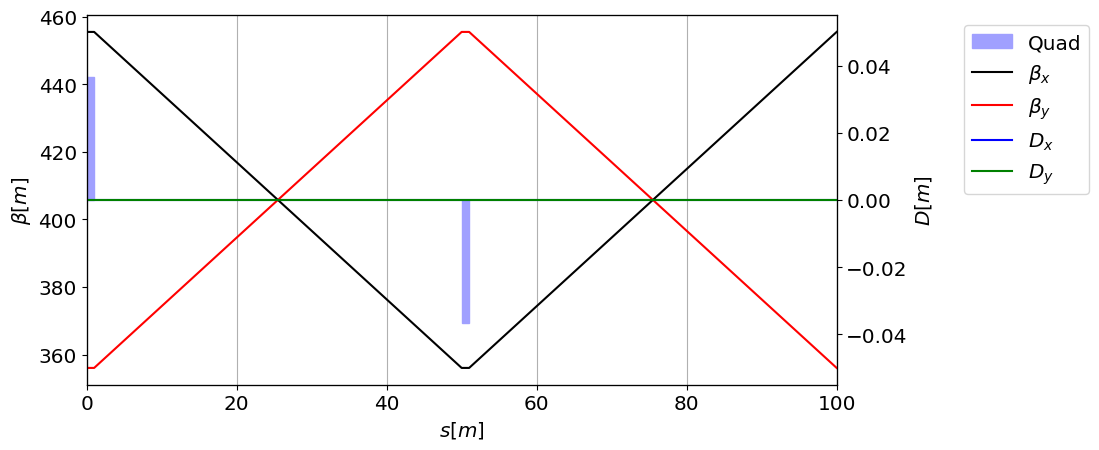

In [17]:
tw.plot(lattice=True, figsize=(12,4.8))

# Question 2

#### **Try to run the Twiss command with a focal length of 20 m.**

<div style="font-size: 16px;">
<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;font-weight: bold;">
    Why do you get an error message?
</div>

In [18]:
env['f']=20

In [19]:
line.get_table(attr=True).k1l

array([ 0.  ,  0.05,  0.  , -0.05,  0.  ,  0.  ])

In [20]:
line.twiss(method='4d', strengths = True)

ValueError: Invalid n1

<div style="font-size: 16px;">
<div style="background-color: #ffff00; padding: 10px; border-radius: 5px;font-weight: bold;">
INTERPRETATION: The cell is unstable due to the fact that the focal length is too short. The stability condition is not satisfied.<p>
    
|Trace(M)|< 2; -1 <= cos $\mu$ <= 1. 
        
In the thin lens approximation f > Lcell/4, being f=20 and Lcell/4=25.
</div>

# **Question 3**

#### **Reduce the focusing strength of the quadrupoles by half.**

<div style="font-size: 16px;">
<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;font-weight: bold;">
    What is its effect on $\beta_{max}$, $\beta_{min}$? 
</div>

In [21]:
env['f']=200

In [22]:
env['k1q1']=myFODO.k1l[myFODO.name=='q1'][0]/env['l_quad']/2

In [23]:
env['k1q2']=myFODO.k1l[myFODO.name=='q2'][0]/env['l_quad']/2

#### **Checking the value of k1:**

In [24]:
line.get_table(attr= True).k1l/env['l_quad']

array([ 0.    ,  0.0025,  0.    , -0.0025,  0.    ,  0.    ])

#### **New Twiss calculation:**

In [25]:
tw2 = line.twiss(method='4d', strengths = True)

In [26]:
#tw2.cols['name s betx alfx mux bety alfy muy'].show(maxwidth = 'full')

#### **Twiss plot combining matplotlib and xsuite method twiss.plot():**

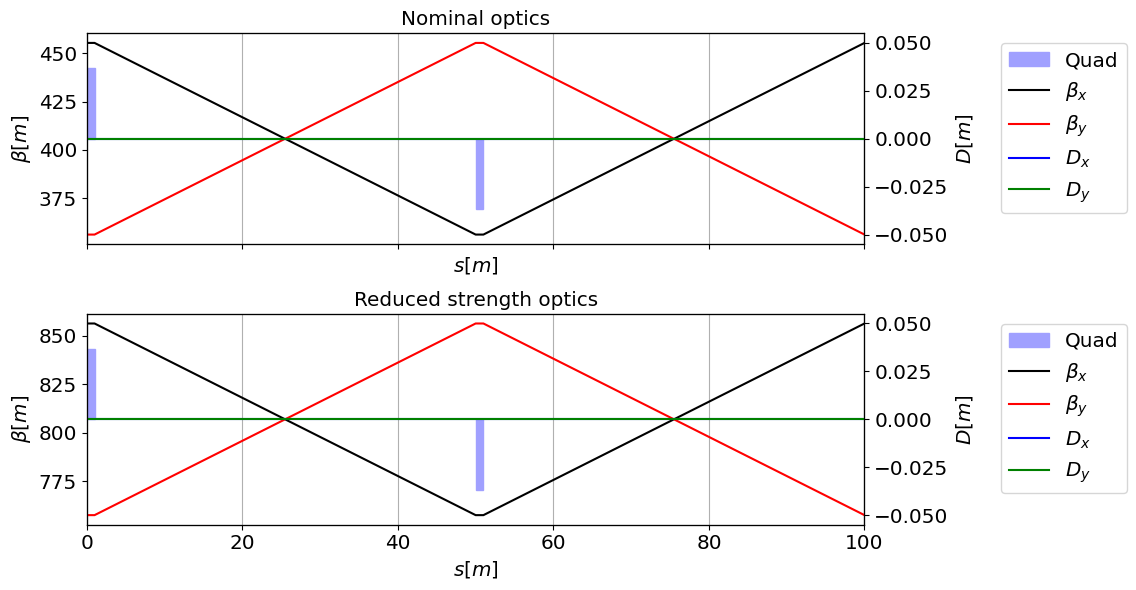

In [27]:
fig, axes = plt.subplots(2,1,figsize=(12,6), sharex=True)

# First twiss 
tw.plot(lattice=True, ax=axes[0])
plt.title("Nominal optics")

# Second twiss
tw2.plot(lattice=True, ax=axes[1])
plt.title("Reduced strength optics")

plt.tight_layout()

<div style="font-size: 16px;">
<div style="background-color: #ffff00; padding: 10px; border-radius: 5px;font-weight: bold;">
  If we reduce the strength of the quadrupoles, k, the $\beta_{max}$, $\beta_{min}$ increase. 
</div>

<div style="font-size: 16px;">
<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;font-weight: bold;">
    And the phase advance $\Delta \mu$?
</div>

**$\mu (s)=\int_0^s \frac{1}{\beta (s)} ds$**

#### **Note that in xsuite, the phase advance is given in units of [2$\pi$].**

In [28]:
np.max(tw.mux)

np.float64(0.03962484408533895)

In [29]:
np.max(tw.muy)

np.float64(0.03962484408533895)

#### **For the second case with reduced k:**

In [30]:
np.max(tw2.mux)

np.float64(0.019774008974246415)

In [31]:
np.max(tw2.mux)*360

np.float64(7.1186432307287095)

#### **Example of plot with matplotlib library:**

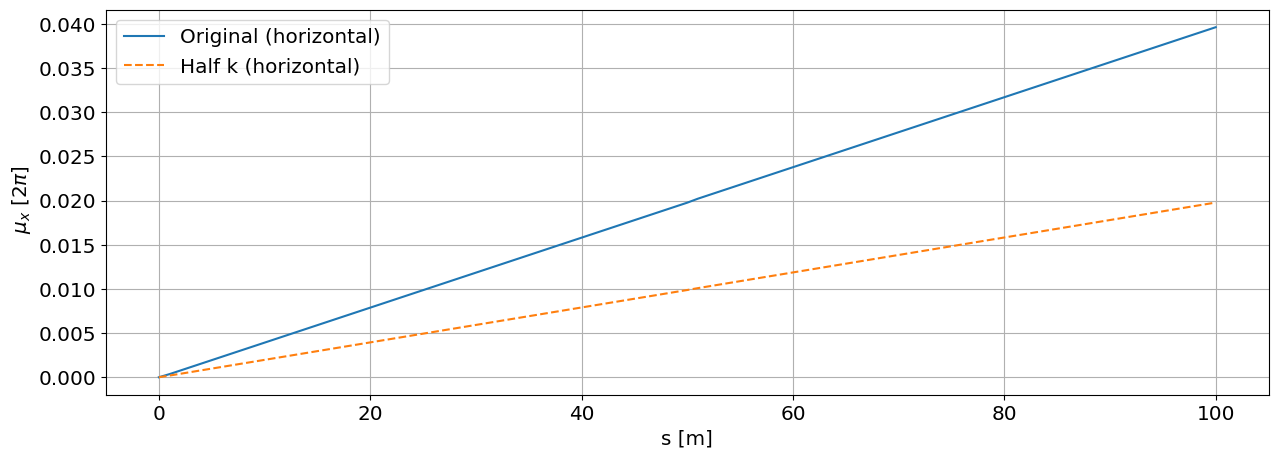

In [32]:
plt.plot(tw.s, tw.mux, label='Original (horizontal)')
plt.plot(tw2.s, tw2.mux, '--', label='Half k (horizontal)')

plt.ylabel(r' $\mu_x$ [2$\pi$]')
plt.xlabel('s [m]')

plt.legend()
plt.grid(True)

plt.show()

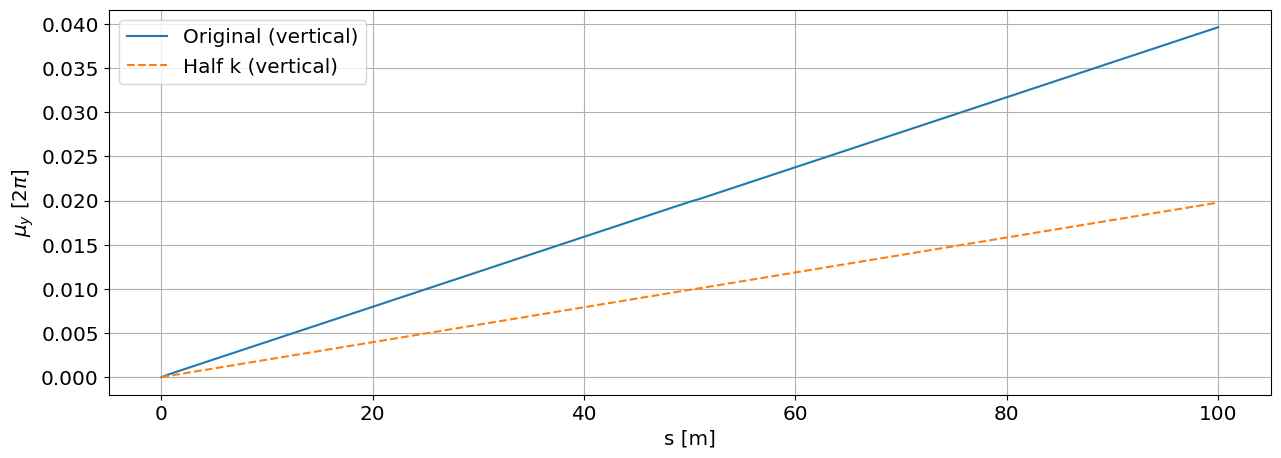

In [33]:
plt.plot(tw.s, tw.muy, label='Original (vertical)')
plt.plot(tw2.s, tw2.muy, '--', label='Half k (vertical)')
plt.ylabel(r'$\mu_y$ [2$\pi$]')
plt.xlabel('s [m]')
plt.legend()
plt.grid(True)

plt.show()

<div style="font-size: 16px;">
<div style="background-color: #ffff00; padding: 10px; border-radius: 5px;font-weight: bold;">
  In the contrary, the phase advance is reduced. This is te effect on the optics when we focus less.
</div>

<div style="font-size: 16px;">
<div style="background-color: #ffe5e5; padding: 10px; border-radius: 5px;font-weight: bold;">
    This behavior is not linear with k. To gain a clearer understanding, you can experiment with different values or use the periodic solution of the FODO cell under the thin lens approximation, as illustrated below.
</div>

<div style="flex: 1;">
    <img src="../Figures/FODOlinear.png" style="max-width: 100%;">
</div>

<div style="font-size: 16px;">
<div style="background-color: #ffff00; padding: 10px; border-radius: 5px;font-weight: bold;">
  It is interesting to note that the $\beta_{max}$ function has a region where it reaches a minimum, which could be an advantageous location. This is because the $\beta_{max}$ value is related to the beam size and, consequently, to the required aperture of the magnets.
</div>

# Question 4

#### **Compute the maximum beam size, $\sigma_{x,y}$, before and after reducing the strength of the quadrupoles:**

$\sigma_{x,y}=\sqrt{\frac{\beta_{x,y}\epsilon_n^{x,y}}{\gamma}}$, **where $\gamma$ stands for the relativistic factor.**

#### **Normalized emittance:**

In [34]:
emittance_n=3e-6 # m*rad

#### **How to get reference beam information? Using the xsuite method "particle_ref"**

In [35]:
line.particle_ref

LineParticleRef(name=None, Particles(q0=1, mass0=9.38e+08, p0c=[4.49999022e+11], gamma0=[479.60501616], beta0=[0.99999783], s=[0.], zeta=[0.], x=[0.], y=[0.], px=[0.], py=[0.], ptau=[0.], delta=[0.], rpp=[1.], rvv=[1.], chi=[1.], charge_ratio=[1.], weight=[1.], ax=[0.], ay=[0.], spin_x=[0.], spin_y=[0.], spin_z=[0.], anomalous_magnetic_moment=[0.], pdg_id=[2212], particle_id=[0], at_element=[0], at_turn=[0], state=[1], parent_particle_id=[0], start_tracking_at_element=np.int64(-1), t_sim=3.34e-07))

In [36]:
pref=line.particle_ref

In [37]:
pref.gamma0

LinkedArrayCpu([479.60501616])

#### **For original optics the maximum beam size is (at the first quadrupole):**

In [38]:
np.sqrt(np.max(tw.betx)*emittance_n/pref.gamma0)

LinkedArrayCpu([0.0016879])

#### **For reduced k**:

In [39]:
np.sqrt(np.max(tw2.betx)*emittance_n/pref.gamma0)

LinkedArrayCpu([0.0023144])

<div style="font-size: 16px;">
<div style="background-color: #ffff00; padding: 10px; border-radius: 5px;font-weight: bold;">
  If we reduce the strength of the quadrupoles, the beam size increases and therefore the required aperture of the magnets. In general, we aim for strong magnets leading to smaller beam pipe and magnets apertures, making them generally less expensive unless we need superconducting technology. 
</div>

# Question 5

#### **My first Transfer Line**
#### Optimize the quadrupole's strength of the transfer line to simultaneously: 

- Increased beam size at the end of the transfer line: $\sigma^{END}_{x,y} = 3 cm$
- Ensure sufficient aperture margin inside the quadrupoles, impose a
  $5\sigma$ safety criterion: $\beta^{quad}_{x,y} < \frac{(0.03/5)^2}{\epsilon_{g}^{x,y}}$


<table style="width:100%; border-collapse:collapse; font-size:16px;">
  <tr>
    <td style="width:50%; vertical-align:top; padding:15px;">
        <strong>Transfer line specifications:</strong>
        <ul>
            <li>L<sub>cell</sub> = 6.4 m</li>
            <li>ld<sub>1</sub> = 1 m, ld<sub>2</sub> = 1 m, ld<sub>3</sub> = 4 m</li>
            <li>L<sub>q</sub> = 0.2 m</li>
            <li> Half aperture of quadrupoles, $r_{in}$ = 0.03 m
            <li> Normal-conducting technology
            <li>Beam specifications: proton, E<sub>k</sub> = 10 MeV/u, $\epsilon_g^{x,y}$= 1.8 mm·mrad 
            <li>Initial TWISS parameters: $\beta_{x}$ = 0.9747 m, $\beta_{y}$ = 0.6867 m, $\alpha_{x}$ = -1.7857, $\alpha_{y}$ = -1.3676
        </ul>
     </td>
        <td style="width:60%; text-align:center; padding:15px;">
        <img src="../Figures/Tutorial1_FODO.png" style="max-width:100%; height:auto;">
    </td>
  </tr>
</table>

##### Note that thee scheme is not in scale it is only for elements display illustration and variables definition


#### **First we build the Transfer Line by changing the initial drift spaces and quadrupole's length:**

In [40]:
# Definition of variables 'ld1', 'ld2','ld3', 'l_quad'
env['ld1']=1
env['ld2']=1
env['ld3']=4

env['l_quad']=0.2
# Beam definition: change energy0 (proton rest mass energy 938.27 MeV/c^2)
line.set_particle_ref('proton', energy0=948.27e6)

#### **New beam information:**

In [41]:
pref = line.particle_ref

#### **We compute and plot the new TWISS functions**

In [42]:
transfer_line_init = line.twiss(start=xt.START, end=xt.END, betx=0.9747, bety=0.6867, alfx= -1.7857, alfy= -1.3676, strengths=True)

#### **Plot:**

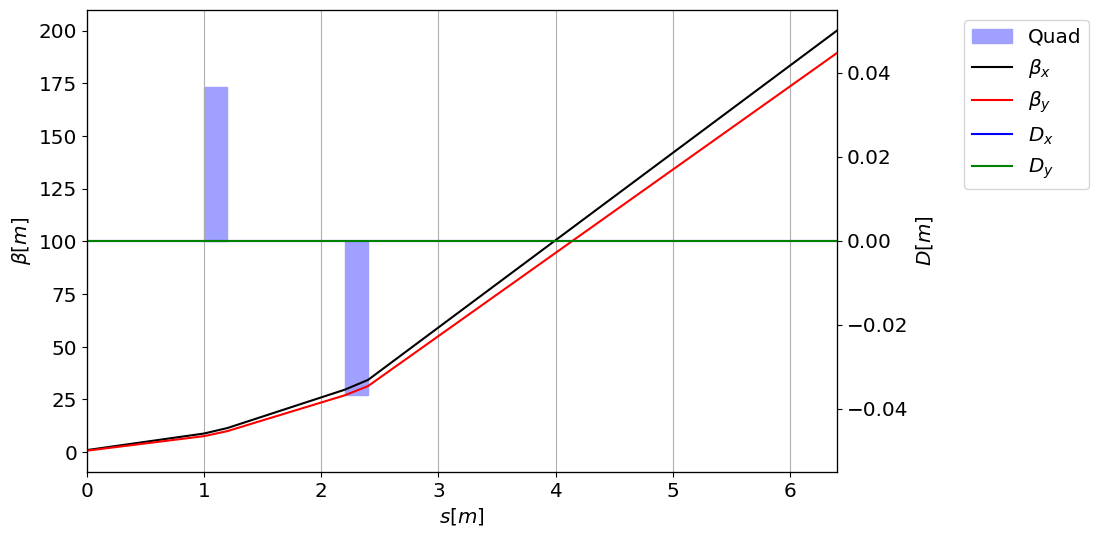

In [43]:
transfer_line_init.plot(figsize=(12,6))

#### **Then, we compute the maximum quadrupole's strength for normal-conducting technology (1.5 T max. B field at the poles):** 


- $k[m^{-2}]=\frac{G[T/m]*0.3}{p[GeV/c]}$
    
- $B_{pole}[T]=G[T/m]*r_{in}[m] $

In [44]:
Gmax=1.5/0.03 # [T/m] for 30 mm radius
kmax=0.3*Gmax/(pref.p0c*1e-9)
kmax

LinkedArrayCpu([109.22029829])

#### **Geometric emittance definition:**

In [45]:
gex=1.8e-7 # m·rad
gey=1.8e-7 # m·rad

#### **Calculation of matching targets:**

$\sigma_{x,y}=\sqrt{\frac{\beta_{x,y}\epsilon_n^{x,y}}{\gamma}}$, **where $\gamma$ stands for the relativistic factor.**

In [46]:
# At the end of the beam line
betax_end=0.03**2/gex
betay_end=0.03**2/gey

# At the quadrupoles
betax_max_quad=(0.03/5)**2/gex
betay_max_quad=(0.03/5)**2/gey

#### **And perform the matching:**

In [47]:
opt = line.match(
    
    start=xt.START, end=xt.END,
    
    init=transfer_line_init,
    

    vary=[
        xt.VaryList(['ld1'], step=1e-1, limits=[0,2]), 
        xt.VaryList(['ld2'], step=1e-1, limits=[0,3]),
        xt.VaryList(['ld3'], step=1e-1, limits=[3,15]),
        xt.VaryList(['k1q1'], step=1e-2, limits=[-100,100]),
        xt.VaryList(['k1q2'], step=1e-2, limits=[-100,100]),       
               
    ],

    targets=[
        xt.TargetSet(betx=betax_end, at=xt.END, tol=1e-7), # First Target of 3 cm at the end of beamline on HORIZONTAl plane
        xt.TargetSet(bety=betay_end, at=xt.END, tol=1e-7), # First Target of 3 cm at the end of beamline on VERTICAL plane
        
        xt.TargetSet('betx', xt.LessThan(betax_max_quad), at='q1'), # Second Target on beam size at quadrupoles 
        xt.TargetSet('bety', xt.LessThan(betay_max_quad), at='q1'), # Second Target on beam size at quadrupoles
        xt.TargetSet('betx', xt.LessThan(betax_max_quad), at='q2'), # Second Target on beam size at quadrupoles
        xt.TargetSet('bety', xt.LessThan(betay_max_quad), at='q2'), # Second Target on beam size at quadrupoles
    ])



                                             
Optimize - start penalty: 6796                              
Matching: model call n. 90 penalty = 5.4917e-08              
Optimize - end penalty:  5.49172e-08                            


In [48]:
opt.vary_status()

Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  ld1            0       1.01074           2             1           0.1             1
1  ON        OK  ld2            0      0.945778           3             1           0.1             1
2  ON        OK  ld3            3       5.14681          15             4           0.1             1
3  ON        OK  k1q1        -100       13.4083         100        0.0025          0.01             1
4  ON        OK  k1q2        -100      -9.47288         100       -0.0025          0.01             1


In [49]:
opt.target_status()

Target status:               nalty = 5.4917e-08              
id state tag      tol_met       residue   current_val target_val    description                                 
0  ON    END_betx    True  -1.64428e-08          5000 5000.0        ('betx', '_end_point'), val=5000, tol=1e ...
1  ON    END_bety    True   5.23978e-08          5000 5000.0        ('bety', '_end_point'), val=5000, tol=1e ...
2  ON    q1_betx     True             0       8.97474 LessThan(200) ('betx', 'q1'), val=LessThan(200), tol=1 ...
3  ON    q1_bety     True             0       7.72145 LessThan(200) ('bety', 'q1'), val=LessThan(200), tol=1 ...
4  ON    q2_betx     True             0       8.47843 LessThan(200) ('betx', 'q2'), val=LessThan(200), tol=1 ...
5  ON    q2_bety     True             0       199.897 LessThan(200) ('bety', 'q2'), val=LessThan(200), tol=1 ...


#### **Then, we compute and plot the new TWISS functions**

In [50]:
TL_after_matching = line.twiss(start=xt.START, end=xt.END, betx=0.9747, bety=0.6867, alfx= -1.7857, alfy= -1.3676, strengths=True)

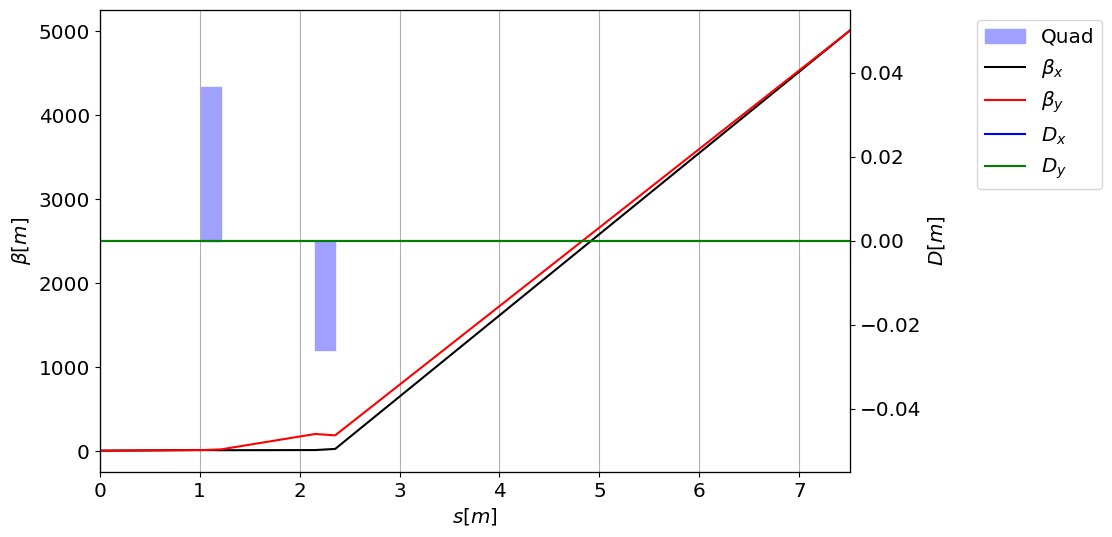

In [51]:
TL_after_matching.plot(figsize=(12,6))

# Question 6

#### Tracking of a matched Gaussian beam

In [52]:
# Matching the initial beam by using the twiss parameters
betx = TL_after_matching.betx[0]
alfx = TL_after_matching.alfx[0]
bety = TL_after_matching.bety[0]
alfy = TL_after_matching.alfy[0]
    
# Beam sizes at the entrance of the transfer line (zero dispersion)
sigma_x  = np.sqrt(betx * gex)
sigma_xp = np.sqrt(gex / betx)
sigma_y  = np.sqrt(bety * gey)
sigma_yp = np.sqrt(gey / bety)

# Number of particles to be tracked
n_part = 10000

# Particle distribution using the numpy method np.random.normal(mean, std, num)
particles = line.build_particles(
    x  = np.random.normal(0, sigma_x,  n_part),
    px = np.random.normal(0, sigma_xp, n_part),
    y  = np.random.normal(0, sigma_y,  n_part),
    py = np.random.normal(0, sigma_yp, n_part),
    delta=np.random.normal(0, 0, n_part)
)

# Saving a copy of the initial particle distribution 
particles_init = particles.copy()

# Tracking
line.track(particles, turn_by_turn_monitor="ONE_TURN_EBE")  # turn_by_turn_monitor="ONE_TURN_EBE" to collect element by element data
data=line.record_last_track

#### **Data inspection:**

#### Tracking data is saved on "Particles" object for all particles at the **end of the beamline** 

In [53]:
particles

Particles(q0=1, mass0=9.38e+08, p0c=[1.37337109e+08, 1.37337109e+08, 1.37337109e+08, ...,
                1.37337109e+08, 1.37337109e+08, 1.37337109e+08],
               shape=(10000,), gamma0=[1.01065566, 1.01065566, 1.01065566, ..., 1.01065566,
                1.01065566, 1.01065566], shape=(10000,), beta0=[0.14482912, 0.14482912, 0.14482912, ..., 0.14482912,
                0.14482912, 0.14482912], shape=(10000,), s=[0., 0., 0., ..., 0., 0., 0.], shape=(10000,), zeta=[-5.80719809e-05, -9.25523591e-05, -1.93116542e-04, ...,
       -1.06913442e-04, -1.19545187e-04, -6.59964220e-05], shape=(10000,), x=[-0.02027467, -0.02106638, -0.00402032, ..., -0.00011273,
       -0.00070791, -0.02392772], shape=(10000,), y=[-0.01197751, -0.01872798, -0.03540446, ..., -0.02666607,
       -0.02794414,  0.00953367], shape=(10000,), px=[-3.64588552e-03, -3.80404389e-03, -7.48135424e-04, ...,
       -1.39001150e-05, -1.11830621e-04, -4.34091105e-03], shape=(10000,), py=[-0.00278497, -0.00434009, -0.00820

In [54]:
particles.x

array([-0.02027467, -0.02106638, -0.00402032, ..., -0.00011273,
       -0.00070791, -0.02392772], shape=(10000,))

In [55]:
particles.px

array([-3.64588552e-03, -3.80404389e-03, -7.48135424e-04, ...,
       -1.39001150e-05, -1.11830621e-04, -4.34091105e-03], shape=(10000,))

#### Tracking data is saved also on "data" object for **all particles** at **all beamline elements** 

In [56]:
data

ParticlesMonitor(start_at_turn=np.int64(0), stop_at_turn=np.int64(6), part_id_start=np.int64(0), part_id_end=np.int64(10000), ebe_mode=np.int64(1), n_records=np.int64(60000), n_repetitions=np.int64(1), repetition_period=np.int64(-1), flag_auto_to_numpy=np.int64(1), data=Particles(q0=0, mass0=0, p0c=[1.37337109e+08, 1.37337109e+08, 1.37337109e+08, ...,
                1.37337109e+08, 1.37337109e+08, 1.37337109e+08],
               shape=(60000,), gamma0=[1.01065566, 1.01065566, 1.01065566, ..., 1.01065566,
                1.01065566, 1.01065566], shape=(60000,), beta0=[0.14482912, 0.14482912, 0.14482912, ..., 0.14482912,
                0.14482912, 0.14482912], shape=(60000,), s=[0.        , 1.01074196, 1.21074196, ..., 2.15651997, 2.35651997,
       7.50332642], shape=(60000,), zeta=[ 0.00000000e+00, -2.78401892e-07, -5.28213805e-07, ...,
       -3.68784471e-06, -4.80824636e-06, -6.59964220e-05], shape=(60000,), x=[ 0.00085789,  0.00039859,  0.00021342, ..., -0.0009719 ,
       -0.0015

In [57]:
# Data of first particle in all locations
data.x[0,:]

array([ 0.00085789,  0.00039859,  0.00021342, -0.00102913, -0.00151   ,
       -0.02027467])

In [58]:
# Data of second particle in all locations
data.x[1,:]

array([ 0.00058895,  0.00065078,  0.0004951 , -0.0009688 , -0.00148771,
       -0.02106638])

In [59]:
# Data of all particle at the q1
data.x[:,0]

array([ 0.00085789,  0.00058895, -0.00031228, ...,  0.0001268 ,
        0.00032628,  0.00028231], shape=(10000,))

#### Plot using **lib.plot_phase_space_bunch** and **lib.track_and_plot_bunch**:

#### **Phase space plot at the entrance and exit of the transfer line:**

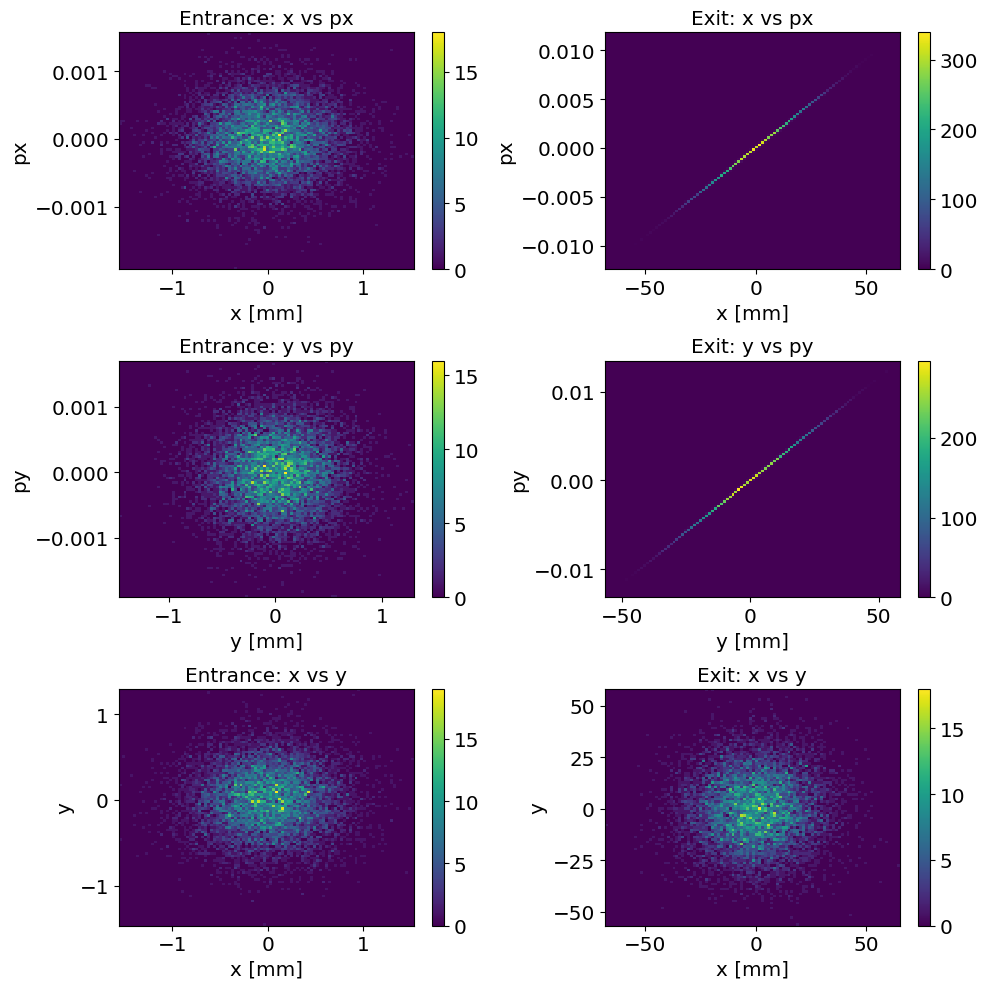

In [60]:
lib.plot_phase_space_bunch(particles_init, particles, nbins=100)

#### **Tracks plot:**

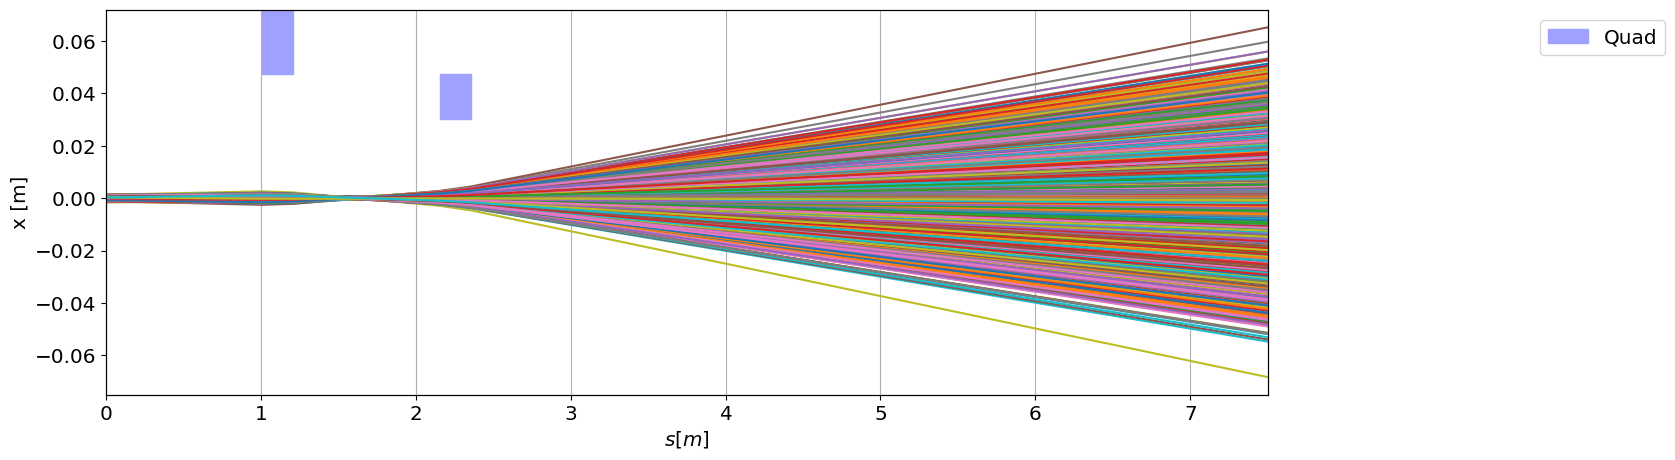

In [61]:
lib.track_and_plot_bunch(data,particles_init,TL_after_matching,'Horizontal')

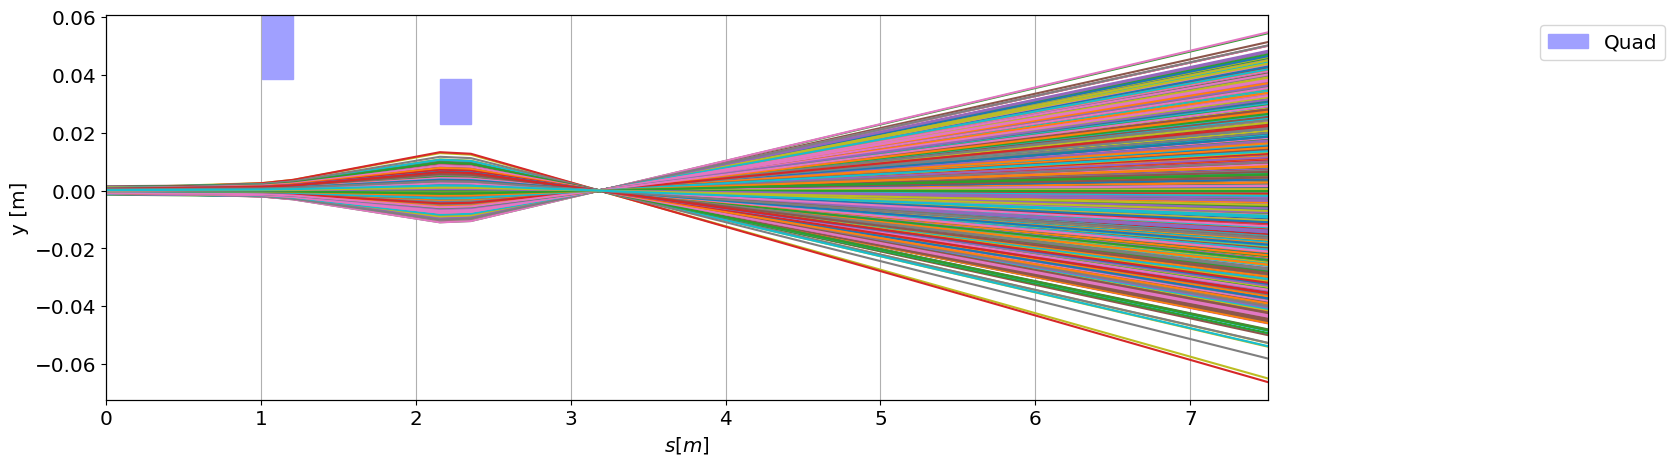

In [165]:
lib.track_and_plot_bunch(data,particles_init,TL_after_matching,'Vertical')